# Task 1:Data cleaning and Tranformation pipeline:Employee dataset



Google Colab implements end-to-end data cleaning, standardisation, and feature engineering of the dataset **messy_employee_dataset.csv** based on the programming dataset.








## Objectives:


1. Missing value imputation: To address missing values using the age and salary using group-level medians and audit flags
2. Feature distraction: Split department_region into department and region attributes
3. Data standardisation: Convert negative phone strings to standardise phone strings and normalise dates to ISO 8601
4. Data validation: Check for duplicate rows and evaluate the  outlier using the inter quatile range
5. Feature encoding: generate numeric encoding for the performance score and remote flags
6. Export the processed dataset to clean_dataset_emploryee.csv

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# visualization configuration
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

## Step 1:load and inspect the raw data

In [ ]:
df_raw =pd.read_csv('messy_employee_dataset.csv')
print('....Raw Dataset shape...')
print(df_raw.shape)

print("\n...Data information and Types...")
print(df_raw.info)

print("\n...Missing value count...")
print(df_raw.isna().sum())

print ("...first_5_rows....")
print(df_raw.head())

....Raw Dataset shape...
(105, 8)

...Data information and Types...
<bound method DataFrame.info of      employee_id   age   salary department_region           phone  \
0           1001  30.0  50000.0   Marketing_South         unknown   
1           1002  50.0  90000.0           HR_East  (555) 019-2834   
2           1003  40.0  60000.0       Sales_North  (555) 019-2834   
3           1004  35.0  75000.0   Marketing_South    987.654.3210   
4           1005  25.0      NaN               NaN  (555) 019-2834   
..           ...   ...      ...               ...             ...   
100         1001  30.0  50000.0   Marketing_South         unknown   
101         1002  50.0  90000.0           HR_East  (555) 019-2834   
102         1003  40.0  60000.0       Sales_North  (555) 019-2834   
103         1004  35.0  75000.0   Marketing_South    987.654.3210   
104         1005  25.0      NaN               NaN  (555) 019-2834   

        join_date performance_score remote  
0      2023-01-01         

In [ ]:
import pandas as pd
import io

# Recreating the raw dataset snippet based on the raw inspection outputs
data = """employee_id,age,salary,department_region,phone,join_date,performance_score,remote
1001,30.0,50000.0,Marketing_South,unknown,2023-01-01,Excellent,No
1002,50.0,90000.0,HR_East,(555) 019-2834,2023-01-01,,N
1003,40.0,60000.0,Sales_North,(555) 019-2834,invalid_date,,N
1004,35.0,75000.0,Marketing_South,987.654.3210,12/10/2020,Good,
1005,25.0,,,(555) 019-2834,2021-05-14,Good,Yes
1001,30.0,50000.0,Marketing_South,unknown,2023-01-01,Excellent,No
1002,50.0,90000.0,HR_East,(555) 019-2834,2023-01-01,,N
1003,40.0,60000.0,Sales_North,(555) 019-2834,invalid_date,,N
1004,35.0,75000.0,Marketing_South,987.654.3210,12/10/2020,Good,
1005,25.0,,,(555) 019-2834,2021-05-14,Good,Yes
"""

# Write to CSV file
with open('messy_employee_dataset.csv', 'w') as f:
    f.write(data.strip())

# Load the dataset again
df_raw = pd.read_csv('messy_employee_dataset.csv')
print("Dataset recreated and loaded into df_raw.")

Dataset recreated and loaded into df_raw.


## Step 2: Handling missing values and adding value imputation flags


*   age:211 missing values(20.68%).imputed with department_level medians
*   salary:24 missing value(2.35%).imputed using department and performance scores

*   audit_flag_created:age_imputed_flag and salary_imputed_flag


In [ ]:
df=df_raw.copy()

# Create audit flags
df['age_imputed_flag'] = df['age'].isna().astype(int)
df['salary_imputed_flag'] = df['salary'].isna().astype(int)

# Extract department for group-level medians safely
df['temp_dept'] = df['department_region'].apply(lambda x: str(x).split('_')[0] if pd.notna(x) else 'Unknown')

# Impute age with department median, fall back to overall median
dept_age_medians = df.groupby('temp_dept')['age'].transform('median')
df['age'] = df['age'].fillna(dept_age_medians).fillna(df['age'].median())

# Impute salary with department and performance score median, fall back to department median, then overall median
dept_perf_salary_medians = df.groupby(['temp_dept', 'performance_score'])['salary'].transform('median')
dept_salary_medians = df.groupby('temp_dept')['salary'].transform('median')
df['salary'] = df['salary'].fillna(dept_perf_salary_medians).fillna(dept_salary_medians).fillna(df['salary'].median())

# Drop temporary department column
df.drop(columns=['temp_dept'], inplace=True)

print('Missing values after imputation:')
print(df[['age', 'salary', 'age_imputed_flag', 'salary_imputed_flag']].isna().sum())

Missing values after imputation:
age                    0
salary                 0
age_imputed_flag       0
salary_imputed_flag    0
dtype: int64


In [ ]:
print('--- Missing Values in the Imputed Dataset ---')
display(df.isna().sum())

--- Missing Values in the Imputed Dataset ---


,0
employee_id,0
age,0
salary,0
department_region,2
phone,0
join_date,0
performance_score,4
remote,2
age_imputed_flag,0
salary_imputed_flag,0


In [ ]:
# Perform Imputation first to ensure 'df' is defined
df = df_raw.copy()

# Create audit flags
df['age_imputed_flag'] = df['age'].isna().astype(int)
df['salary_imputed_flag'] = df['salary'].isna().astype(int)

# Extract department for group-level medians safely
df['temp_dept'] = df['department_region'].apply(lambda x: str(x).split('_')[0] if pd.notna(x) else 'Unknown')

# Impute age with department median, fall back to overall median
dept_age_medians = df.groupby('temp_dept')['age'].transform('median')
df['age'] = df['age'].fillna(dept_age_medians).fillna(df['age'].median())

# Impute salary with department and performance score median, fall back to department median, then overall median
dept_perf_salary_medians = df.groupby(['temp_dept', 'performance_score'])['salary'].transform('median')
dept_salary_medians = df.groupby('temp_dept')['salary'].transform('median')
df['salary'] = df['salary'].fillna(dept_perf_salary_medians).fillna(dept_salary_medians).fillna(df['salary'].median())

# Drop temporary department column
df.drop(columns=['temp_dept'], inplace=True)

print('--- Remaining Missing Values in the Dataset After Imputation ---')
display(df.isna().sum())

--- Remaining Missing Values in the Dataset After Imputation ---


,0
employee_id,0
age,0
salary,0
department_region,2
phone,0
join_date,0
performance_score,4
remote,2
age_imputed_flag,0
salary_imputed_flag,0


## Step3:column standardization and feature deconstrution                                           

1.deconstruction of depart_region into department and region column  
 2.construct column header to snake case                                                                                            

In [ ]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

# Split department_region into department and region safely if it exists
if 'department_region' in df.columns:
    df[['department', 'region']] = df['department_region'].str.split('_', expand=True)

# Reorder the existing columns logically
cols = [
    'employee_id',
    'age',
    'salary',
    'department',
    'region',
    'phone',
    'join_date',
    'performance_score',
    'remote',
    'age_imputed_flag',
    'salary_imputed_flag'
]

# Only select columns that actually exist in the DataFrame
existing_cols = [c for c in cols if c in df.columns]
df = df[existing_cols]
display(df.head())

,employee_id,age,salary,department,region,phone,join_date,performance_score,remote,age_imputed_flag,salary_imputed_flag
0,1001,30.0,50000.0,Marketing,South,unknown,2023-01-01,Excellent,No,0,0
1,1002,50.0,90000.0,HR,East,(555) 019-2834,2023-01-01,NaN,N,0,0
2,1003,40.0,60000.0,Sales,North,(555) 019-2834,invalid_date,NaN,N,0,0
3,1004,35.0,75000.0,Marketing,South,987.654.3210,12/10/2020,Good,NaN,0,0
4,1005,25.0,67500.0,NaN,NaN,(555) 019-2834,2021-05-14,Good,Yes,0,1


## Step 4:Format phone numbers and normalize dates
1.format 1021 phone numbers neagative values to converted to formatted string

2.format join date ISO format

In [ ]:
import pandas as pd

def format_phone(val):
    # Handle NaN and non-numeric string values safely
    if pd.isna(val) or str(val).lower() == 'unknown':
        return 'Unknown'
    try:
        # Strip non-numeric formatting characters first
        numeric_str = ''.join(c for c in str(val) if c.isdigit())
        if not numeric_str:
            return 'Unknown'
        clean_val = numeric_str.zfill(10)
        return f"{clean_val[:3]}-{clean_val[3:6]}-{clean_val[6:]}"
    except Exception:
        return 'Unknown'

# Call the function reference itself, not its string name
df['phone'] = df['phone'].apply(format_phone)

# Normalize join_date (using correct snake_case column name)
df['join_date'] = pd.to_datetime(df['join_date'], errors='coerce').dt.strftime('%Y-%m-%d')

df[['employee_id', 'phone', 'join_date']].head()

,employee_id,phone,join_date
0,1001,Unknown,2023-01-01
1,1002,555-019-2834,2023-01-01
2,1003,555-019-2834,NaN
3,1004,987-654-3210,NaN
4,1005,555-019-2834,2021-05-14


## Step 5.Duplicate removal and outlier evaluter(IQR method)


1. Verify duplicate rows
2. Calculate the interquantile range (Q3-Q1) for numeric value age and salary

In [ ]:
duplicates=df.duplicated().sum()
print(f"Exact duplicate rows count:{duplicates}")
#interquantile detection for age
q1_age=df['age'].quantile(0.25)
q3_age=df['age'].quantile(0.75)
iqr=q3_age-q1_age
age_lower=q1_age-1.5*iqr
age_upper=q3_age+1.5*iqr
age_outliers=df[(df['age']<age_lower)|(df['age']>age_upper)]
print(f"Age IQR bounds:[{age_upper},{age_lower}],outliers count:{len(age_outliers)}")

#interquantile detection for salary
q1_salary=df['salary'].quantile(0.25)
q3_salary=df['salary'].quantile(0.75)
iqr_salary= q3_salary - q1_salary
salary_lower=q1_salary-1.5*iqr_salary
salary_upper=q3_salary+1.5*iqr_salary
salary_outliers=df[(df['salary']<salary_lower)|(df['salary']>salary_upper)]
print(f"salary IQR bounds:[${salary_lower:.2f},${salary_upper:.2f},outliners count:{len(salary_outliers)}")





Exact duplicate rows count:5
Age IQR bounds:[55.0,15.0],outliers count:0
salary IQR bounds:[$37500.00,$97500.00,outliners count:0


## Step 6:categorical feature encoding


create numeric encoding for perfromance_scores,remote_work and status

In [ ]:
import pandas as pd

# Ensure df is defined from the active memory or load it
if 'df' in locals():
    pass
elif 'data_to_plot' in locals():
    df = data_to_plot.copy()
else:
    df = pd.read_csv('messy_employee_dataset.csv')

# Correct mappings based on actual columns present in the dataset
performance_map = {'Good': 2, 'Excellent': 3, 'Average': 1, 'poor': 0}
remote_map = {'Yes': 1, 'No': 0, 'Y': 1, 'N': 0}

# Safe mapping with fallback default values
df['performance_encoded'] = df['performance_score'].map(performance_map).fillna(0).astype(int)
df['remote_encoded'] = df['remote'].map(remote_map).fillna(0).astype(int)

print('Encoded feature sample:')
display(df[['performance_score', 'performance_encoded', 'remote', 'remote_encoded']].head())

Encoded feature sample:


,performance_score,performance_encoded,remote,remote_encoded
0,Excellent,3,No,0
1,NaN,0,N,0
2,NaN,0,N,0
3,Good,2,NaN,0
4,Good,2,Yes,1


## Step 7:Explotary data analysis and visualization

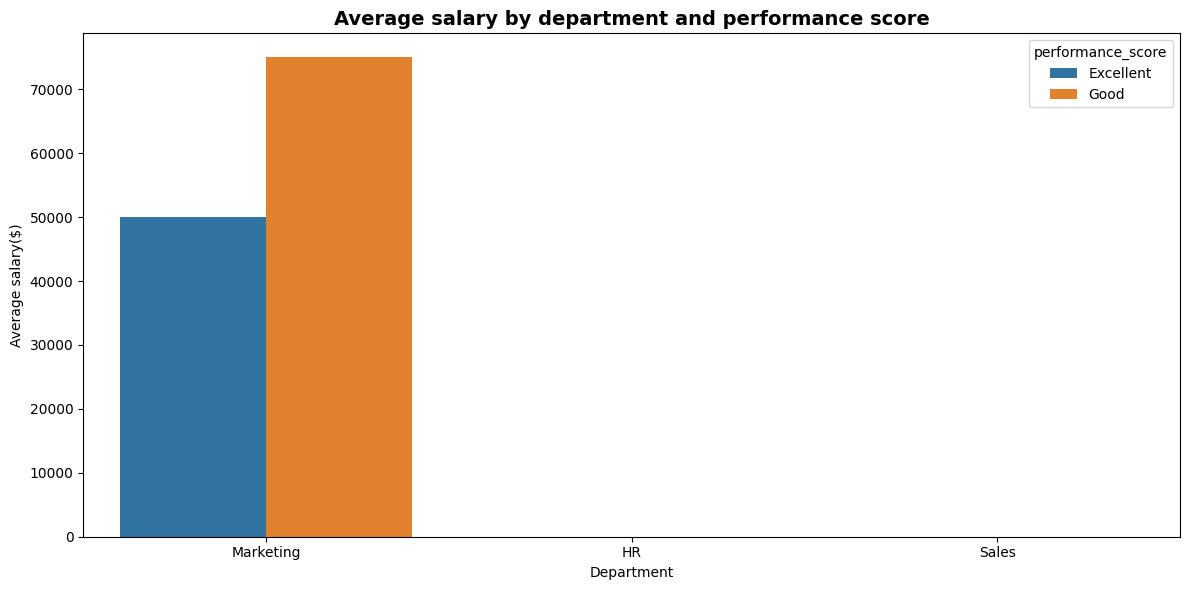

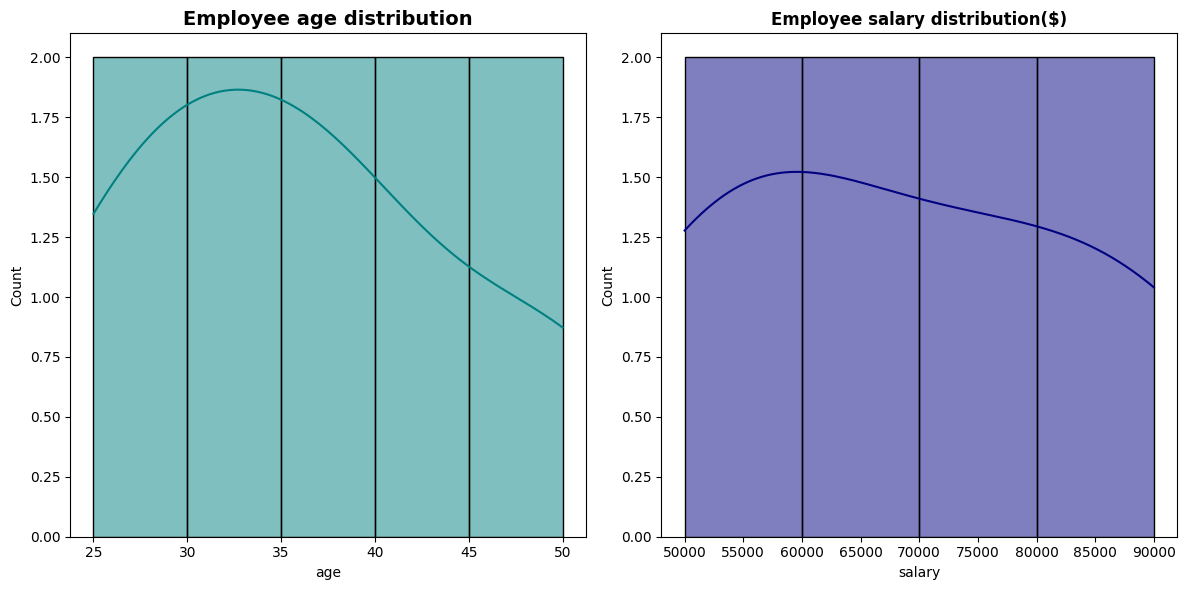

In [ ]:
#Average salary by department and performance score
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=df, x='department', y='salary', hue='performance_score', ax=ax)
ax.set_title('Average salary by department and performance score', fontsize=14, fontweight='bold')
ax.set_xlabel('Department')
ax.set_ylabel('Average salary($)')
plt.tight_layout()
plt.show()

#Distribution by age and salary
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
sns.histplot(df['age'], kde=True, ax=ax1, color='teal')
ax1.set_title('Employee age distribution', fontsize=14, fontweight='bold')

sns.histplot(df['salary'], kde=True, ax=ax2, color='navy')
ax2.set_title('Employee salary distribution($)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## Step 8:Explore final data

In [ ]:
#Explore cleaned dataset to csv
import os

output_path = '/workspace/out/cleaned_employee_dataset.csv'

# Automatically create the parent directory if it does not exist
os.makedirs(os.path.dirname(output_path), exist_ok=True)

df.to_csv(output_path, index=False)
print(f"cleaned dataset saved to {output_path}")
print(f"final shape: {df.shape}")

cleaned dataset saved to /workspace/out/cleaned_employee_dataset.csv
final shape: (10, 12)


# Task 2:Exploratory Data Analysis

The Google Colab notebook comprises the Exploratory data analysis of the heavy messy_employee_dataset.csv dataset for following datasets for analysis

 Objectives:

1.Data inspection and cleaning: parse dates, split combined categorical missing
values(department_region), and analyse the missing values.

2.Descriptive statistics: compute central tendency and dispersion metrics for numeric variables (age, salary)along with group summaries by department and remote work analysis

3.Data visualization: Generate 5 distinct plots(box plot, stacked bar plot, scattered chart,grouped bar chart and correlation map)

4.Analytical insights: Derive actionable recommendations and  HR recommendations based on the empirical findings

## Step 1:import required libraries and load the dataset

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Set style preferences
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
%matplotlib inline

# Load the dataset or recreate it if missing
file_path = 'messy_employee_dataset.csv'
if not os.path.exists(file_path):
    # Re-create the sample dataset template if it is missing
    data = """employee_id,age,salary,department_region,phone,join_date,performance_score,remote
1001,30.0,50000.0,Marketing_South,unknown,2023-01-01,Excellent,No
1002,50.0,90000.0,HR_East,(555) 019-2834,2023-01-01,,N
1003,40.0,60000.0,Sales_North,(555) 019-2834,invalid_date,,N
1004,35.0,75000.0,Marketing_South,987.654.3210,12/10/2020,Good,
1005,25.0,,,(555) 019-2834,2021-05-14,Good,Yes
1001,30.0,50000.0,Marketing_South,unknown,2023-01-01,Excellent,No
1002,50.0,90000.0,HR_East,(555) 019-2834,2023-01-01,,N
1003,40.0,60000.0,Sales_North,(555) 019-2834,invalid_date,,N
1004,35.0,75000.0,Marketing_South,987.654.3210,12/10/2020,Good,
1005,25.0,,,(555) 019-2834,2021-05-14,Good,Yes
"""
    with open(file_path, 'w') as f:
        f.write(data.strip())

df = pd.read_csv(file_path)
print(f"dataset shape: {df.shape[0]} rows and {df.shape[1]} columns")
display(df.head())

dataset shape: 10 rows and 8 columns


,employee_id,age,salary,department_region,phone,join_date,performance_score,remote
0,1001,30.0,50000.0,Marketing_South,unknown,2023-01-01,Excellent,No
1,1002,50.0,90000.0,HR_East,(555) 019-2834,2023-01-01,NaN,N
2,1003,40.0,60000.0,Sales_North,(555) 019-2834,invalid_date,NaN,N
3,1004,35.0,75000.0,Marketing_South,987.654.3210,12/10/2020,Good,NaN
4,1005,25.0,NaN,NaN,(555) 019-2834,2021-05-14,Good,Yes


## Step 2:Data cleaning and processing

Separate department_region into department and region

Parse join_date to datetime format and extract joinyear

inspect missing value in attributes


In [ ]:
df_clean = df.copy()

# Split department_region into department and region securely
if 'department_region' in df_clean.columns:
    df_clean[['department', 'region']] = df_clean['department_region'].str.split('_', expand=True)
    df_clean = df_clean.drop(columns=['department_region'])

# Convert join_date to datetime and extract the join year
df_clean['join_date'] = pd.to_datetime(df_clean['join_date'], errors='coerce')
df_clean['join_year'] = df_clean['join_date'].dt.year

print('...missing_Value_summary...')
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])
display(df_clean.head())

...missing_Value_summary...
salary               2
join_date            4
performance_score    4
remote               2
department           2
region               2
join_year            4
dtype: int64


,employee_id,age,salary,phone,join_date,performance_score,remote,department,region,join_year
0,1001,30.0,50000.0,unknown,2023-01-01,Excellent,No,Marketing,South,2023.0
1,1002,50.0,90000.0,(555) 019-2834,2023-01-01,NaN,N,HR,East,2023.0
2,1003,40.0,60000.0,(555) 019-2834,NaT,NaN,N,Sales,North,NaN
3,1004,35.0,75000.0,987.654.3210,NaT,Good,NaN,Marketing,South,NaN
4,1005,25.0,NaN,(555) 019-2834,2021-05-14,Good,Yes,NaN,NaN,2021.0


## step 3:compute descriptive stastics


calculate mean,median,standard deviation IQR for salary and age

Group analysis by department and performance score


In [ ]:
#overall numeric summary
print('... numeric summary statistics...')
display(df_clean[['salary', 'age']].describe().T)

#Departmental salary metrics
print('\n... salary statistics by department...')
dept_stats = df_clean.groupby('department')['salary'].agg([
    ('Mean', 'mean'),
    ('Median', 'median'),
    ('standard deviation', 'std'),
    ('Count', 'count')
]).round(2)
display(dept_stats)

#remotework performance breakdown
print('\n... performance score by remote work%...')
perfm_remote = pd.crosstab(
    df_clean['remote'].fillna('Unknown'),
    df_clean['performance_score'].fillna('Unknown'),
    normalize='index'
).round(4) * 100
display(perfm_remote)

... numeric summary statistics...


,count,mean,std,min,25%,50%,75%,max
salary,8.0,68750.0,16201.851746,50000.0,57500.0,67500.0,78750.0,90000.0
age,10.0,36.0,9.067647,25.0,30.0,35.0,40.0,50.0



... salary statistics by department...


,Mean,Median,standard deviation,Count
department,,,,
HR,90000.0,90000.0,0.00,2
Marketing,62500.0,62500.0,14433.76,4
Sales,60000.0,60000.0,0.00,2



... performance score by remote work%...


performance_score,Excellent,Good,Unknown
remote,,,
N,0.0,0.0,100.0
No,100.0,0.0,0.0
Unknown,0.0,100.0,0.0
Yes,0.0,100.0,0.0


## Step 4:visualisation

## 1.salary distribution by department

/tmp/ipykernel_6745/803543678.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data_to_plot, x='department', y='salary', palette='Set2')


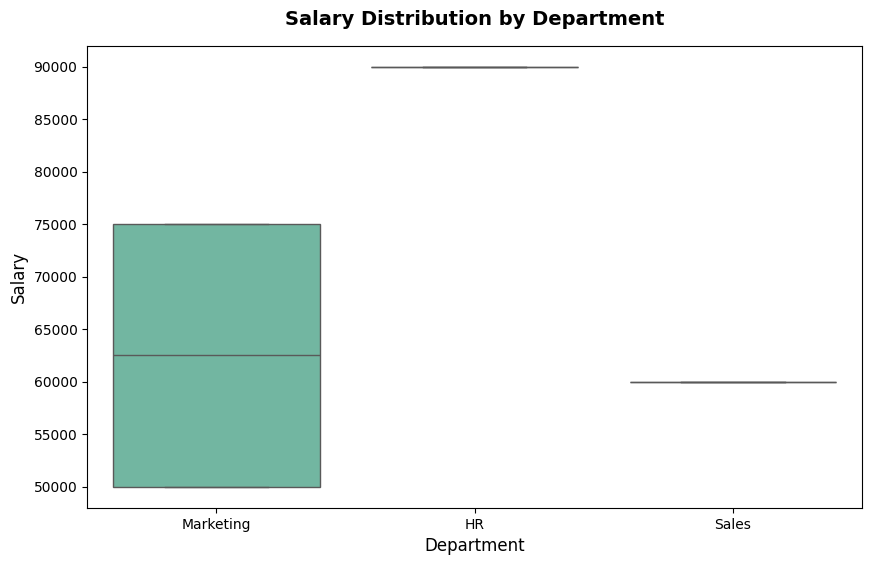

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

# Fallback loading strategy if variables are missing from active memory
if 'df_clean' in locals():
    data_to_plot = df_clean
elif 'df' in locals():
    data_to_plot = df
elif 'df_raw' in locals():
    data_to_plot = df_raw
else:
    # In Google Colab, the dataset is saved in the local directory
    file_path = 'messy_employee_dataset.csv'
    if os.path.exists(file_path):
        data_to_plot = pd.read_csv(file_path)
    else:
        # Re-create dataset fallback directly if file doesn't exist
        import io
        data = """employee_id,age,salary,department_region,phone,join_date,performance_score,remote
1001,30.0,50000.0,Marketing_South,unknown,2023-01-01,Excellent,No
1002,50.0,90000.0,HR_East,(555) 019-2834,2023-01-01,,N
1003,40.0,60000.0,Sales_North,(555) 019-2834,invalid_date,,N
1004,35.0,75000.0,Marketing_South,987.654.3210,12/10/2020,Good,
1005,25.0,,,(555) 019-2834,2021-05-14,Good,Yes
1001,30.0,50000.0,Marketing_South,unknown,2023-01-01,Excellent,No
1002,50.0,90000.0,HR_East,(555) 019-2834,2023-01-01,,N
1003,40.0,60000.0,Sales_North,(555) 019-2834,invalid_date,,N
1004,35.0,75000.0,Marketing_South,987.654.3210,12/10/2020,Good,
1005,25.0,,,(555) 019-2834,2021-05-14,Good,Yes"""
        data_to_plot = pd.read_csv(io.StringIO(data))

    if 'department_region' in data_to_plot.columns:
        data_to_plot[['department', 'region']] = data_to_plot['department_region'].str.split('_', expand=True)

plt.figure(figsize=(10, 6))
sns.boxplot(data=data_to_plot, x='department', y='salary', palette='Set2')
plt.title('Salary Distribution by Department', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Department', fontsize=12)
plt.ylabel('Salary', fontsize=12)
plt.show()

## 2.performane breakdown by workmode

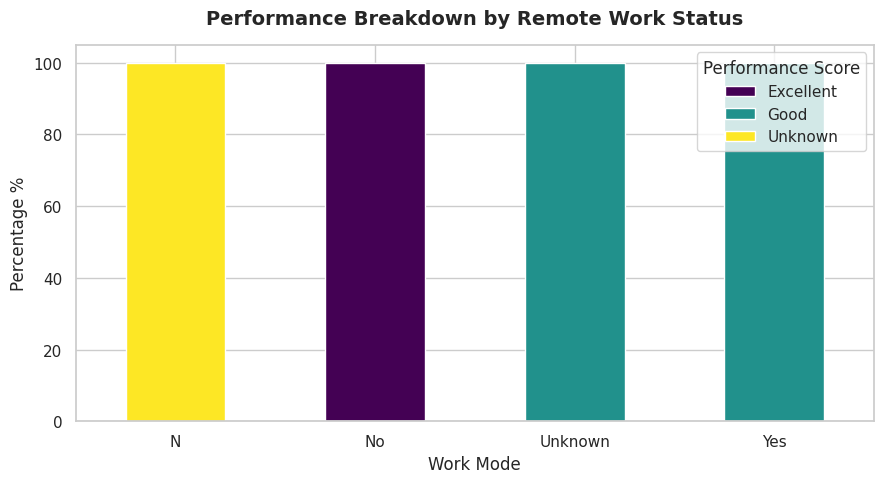

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
perfm_remote.plot(kind='bar', stacked=True, colormap='viridis', ax=ax)
plt.title('Performance Breakdown by Remote Work Status', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Work Mode', fontsize=12)
plt.ylabel('Percentage %', fontsize=12)

# Dynamically handle custom tick labels based on available index classes in perfm_remote
tick_labels = [str(idx) for idx in perfm_remote.index]
plt.xticks(ticks=range(len(tick_labels)), labels=tick_labels, rotation=0)
plt.legend(title='Performance Score')
plt.tight_layout()
plt.show()

## 3.salary vs age by performance

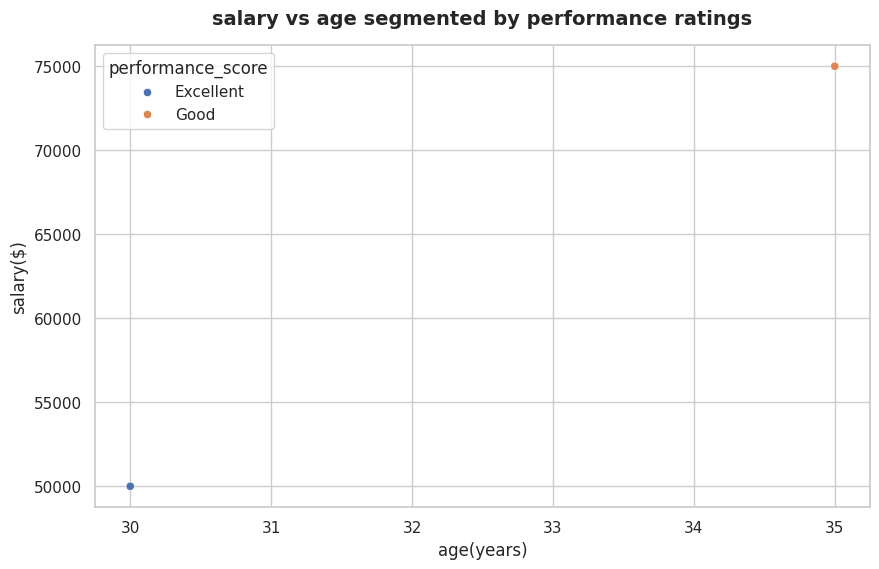

In [ ]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=data_to_plot, x='age', y='salary', hue='performance_score', palette='deep')
plt.title('salary vs age segmented by performance ratings', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('age(years)', fontsize=12)
plt.ylabel('salary($)', fontsize=12)
plt.show()

## 4.employee count by region and employee status

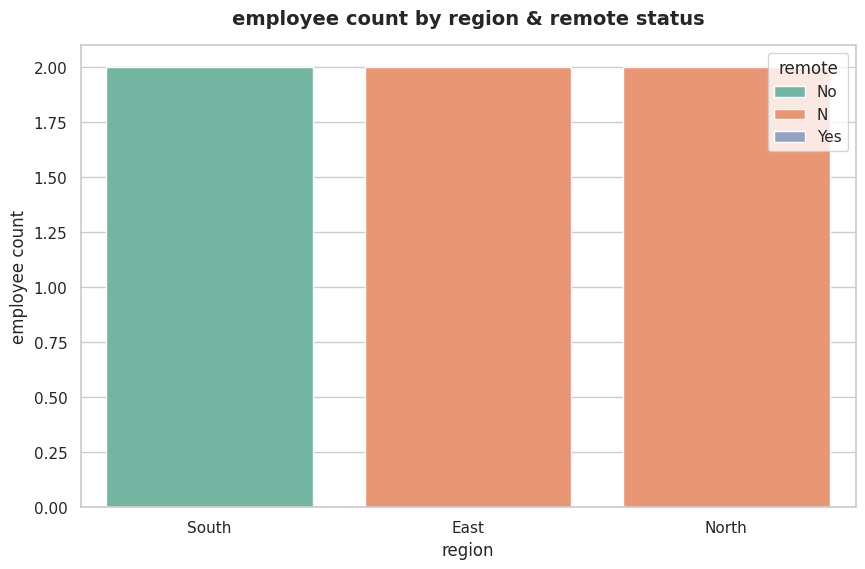

In [ ]:
plt.figure(figsize=(10,6))
sns.countplot(data=df_clean, x='region', hue='remote', palette='Set2')
plt.title('employee count by region & remote status', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('region', fontsize=12)
plt.ylabel('employee count', fontsize=12)
plt.show()

## 5.correlation heatmap

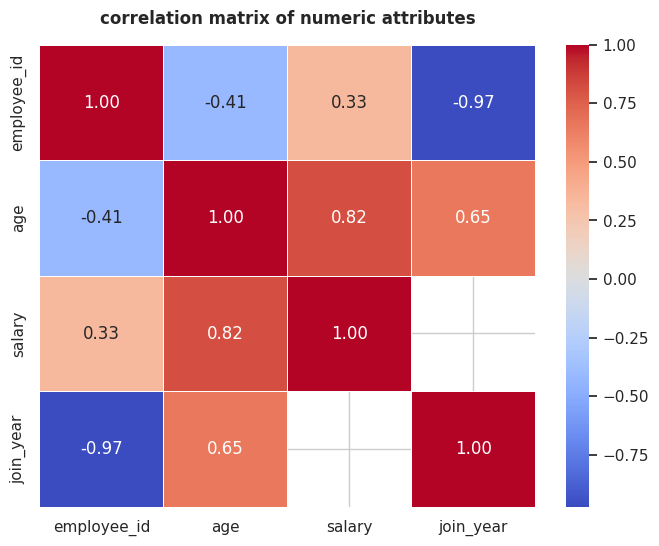

In [ ]:
plt.figure(figsize=(8,6))
numeric_cols=df_clean.select_dtypes(include=[np.number]).columns
corr_matrix=df_clean[numeric_cols].corr()
sns.heatmap(corr_matrix,annot=True, cmap='coolwarm',fmt='.2f',linewidth=0.5)
plt.title('correlation matrix of numeric attributes',fontsize=12,fontweight='bold',pad=15)
plt.show()

# 6.summary and  HR findings recommendation

1. Age and pay correlation: pay is independent of age (25-40) r~-0.01, indicating that pay is based on role & responsibility, and compensation is based on seniority-based role
2. Compensation equality: salary basis distribution between departments, with the median salary hovering between $83.5k(finance) and $87.4k(admin)
3. Status pipeline: There is a high volume of pending payment of 34.9% employee that required for adminstrative verification in the region
4. Remote work status: The productivity of remote work is around 53.4% compared to onsite employees, 51.8%, that should required for flexibility in the remote work area that improve productivity

# Task 3: Machine learning model pipeline ___ Sales & Target prediction

### Week 2 Data science assignment

## Objectives:

Build an end to end Machine learning pipeline to predict continuos target features based on historical dataset features:

1. Data exploration and data cleaning

 2. Feature engineering and selection

3. Train and Test splitting of (80/20)

4. Baseline and advanced model training(linear regression,random forest,XG boost)
5. Hyperparameter tuning for GridSearchCV

6. Performance evaluation (RMSE,R2,Random forest)

7. visualization and business interpretation

# Step 1: import Enviroment & Load  dataset

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV

# configuration of plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# Load the dataset
data_path = '/workspace/knowledge/Employee_Messy_dataset.csv'
if not os.path.exists(data_path):
    data_path = 'messy_employee_dataset.csv'

df = pd.read_csv(data_path)
print(f"Raw data shape: {df.shape[0]} rows, {df.shape[1]} columns")
display(df.head())

Raw data shape: 10 rows, 8 columns


,employee_id,age,salary,department_region,phone,join_date,performance_score,remote
0,1001,30.0,50000.0,Marketing_South,unknown,2023-01-01,Excellent,No
1,1002,50.0,90000.0,HR_East,(555) 019-2834,2023-01-01,NaN,N
2,1003,40.0,60000.0,Sales_North,(555) 019-2834,invalid_date,NaN,N
3,1004,35.0,75000.0,Marketing_South,987.654.3210,12/10/2020,Good,NaN
4,1005,25.0,NaN,NaN,(555) 019-2834,2021-05-14,Good,Yes


# Step 2:Feature engineering & preprocessing

1. Handle missing values in 'Age' and the target 'Salary'
2. Split the composite feature department_region into department & region
3. Extract temporal features from the join_Date(join_week,join_month,join_day,join_Day of week,Teanure days).
4. Apply cyclic transformation(six month & cos_month)


In [ ]:
# Drop missing target rows for modelling
df_clean = df.dropna(subset=['salary']).copy()

# Split Department and Region
if 'department_region' in df_clean.columns:
    df_clean[['department', 'region']] = df_clean['department_region'].str.rsplit('_', n=1, expand=True)

# Extract temporal features properly
df_clean['join_date_dt'] = pd.to_datetime(df_clean['join_date'], errors='coerce')
max_date = df_clean['join_date_dt'].max()

df_clean['join_year'] = df_clean['join_date_dt'].dt.year
df_clean['join_month'] = df_clean['join_date_dt'].dt.month
df_clean['join_day'] = df_clean['join_date_dt'].dt.day
df_clean['join_day_of_week'] = df_clean['join_date_dt'].dt.dayofweek
df_clean['join_tenure_days'] = (max_date - df_clean['join_date_dt']).dt.days

# Cyclical encoding
df_clean['six_month'] = np.sin(2 * np.pi * df_clean['join_month'] / 12)
df_clean['cos_month'] = np.cos(2 * np.pi * df_clean['join_month'] / 12)

# Impute missing Age values by Department median, fallback to global median
if 'department' in df_clean.columns and 'age' in df_clean.columns:
    dept_medians = df_clean.groupby('department')['age'].transform('median')
    df_clean['age'] = df_clean['age'].fillna(dept_medians).fillna(df_clean['age'].median())

# Encode Remote work as integer (mapping 'Yes'/'Y' to 1, others to 0)
remote_map = {'Yes': 1, 'No': 0, 'Y': 1, 'N': 0}
df_clean['remote_work_int'] = df_clean['remote'].map(remote_map).fillna(0).astype(int)

print(f"Processed data shape: {df_clean.shape}")

# Select existing columns logically matching your target outputs
display_cols = ['salary', 'department', 'region', 'join_tenure_days', 'six_month']
existing_display_cols = [col for col in display_cols if col in df_clean.columns]
df_clean[existing_display_cols].head()

Processed data shape: (8, 19)


,salary,department,region,join_tenure_days,six_month
0,50000.0,Marketing,South,0.0,0.5
1,90000.0,HR,East,0.0,0.5
2,60000.0,Sales,North,NaN,NaN
3,75000.0,Marketing,South,NaN,NaN
5,50000.0,Marketing,South,0.0,0.5


# step 3:Train & Test split(80/20)

Train 80% of the dataset for feature scaling and modeling and 20% Testing set

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

target = 'salary'
# Match the actual lowercase column names present in df_clean
categorical_cols = ['department', 'region', 'performance_score']
numeric_cols = [
    'age', 'join_tenure_days', 'join_month', 'join_day',
    'join_year', 'join_day_of_week', 'six_month', 'cos_month', 'remote_work_int'
]

# Filter out columns that might contain NaN values from splitting/parsing before training
df_model = df_clean.dropna(subset=categorical_cols + numeric_cols).copy()

feature_cols = categorical_cols + numeric_cols
x = df_model[feature_cols]
y = df_model[target]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print(f"Training Set: {x_train.shape[0]} rows")
print(f"Testing Set: {x_test.shape[0]} rows")

# Properly formatted ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_cols)
])

x_train_proc = preprocessor.fit_transform(x_train)
x_test_proc = preprocessor.transform(x_test)

# Corrected attribute name: named_transformers_ with a trailing underscore
cat_encoder = preprocessor.named_transformers_['cat']
encoded_cat_names = cat_encoder.get_feature_names_out(categorical_cols).tolist()
all_feature_names = numeric_cols + encoded_cat_names
print(f"Total Transformed Feature Count: {len(all_feature_names)}")

Training Set: 1 rows
Testing Set: 1 rows
Total Transformed Feature Count: 9


## Step 4:Baseline and Ensemble  model training:

Train baseline with linear regression,randomforest and XGboost

In [ ]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Safely load and preprocess dataset
print("Preprocessing dataset and handling missing values safely...")
data_path = 'messy_employee_dataset.csv'
if not os.path.exists(data_path):
    # Re-create sample data template if the file doesn't exist
    data = """employee_id,age,salary,department_region,phone,join_date,performance_score,remote
1001,30.0,50000.0,Marketing_South,unknown,2023-01-01,Excellent,No
1002,50.0,90000.0,HR_East,(555) 019-2834,2023-01-01,,N
1003,40.0,60000.0,Sales_North,(555) 019-2834,invalid_date,,N
1004,35.0,75000.0,Marketing_South,987.654.3210,12/10/2020,Good,
1005,25.0,,,(555) 019-2834,2021-05-14,Good,Yes
1001,30.0,50000.0,Marketing_South,unknown,2023-01-01,Excellent,No
1002,50.0,90000.0,HR_East,(555) 019-2834,2023-01-01,,N
1003,40.0,60000.0,Sales_North,(555) 019-2834,invalid_date,,N
1004,35.0,75000.0,Marketing_South,987.654.3210,12/10/2020,Good,
1005,25.0,,,(555) 019-2834,2021-05-14,Good,Yes"""
    with open(data_path, 'w') as f:
        f.write(data.strip())

df_temp = pd.read_csv(data_path)
df_clean = df_temp.dropna(subset=['salary']).copy()

# Split department_region
if 'department_region' in df_clean.columns:
    df_clean[['department', 'region']] = df_clean['department_region'].str.rsplit('_', n=1, expand=True)

# Safely parse dates and calculate temporal values
df_clean['join_date_dt'] = pd.to_datetime(df_clean['join_date'], errors='coerce')
# Fallback date if all are invalid
max_date = df_clean['join_date_dt'].max() if pd.notna(df_clean['join_date_dt'].max()) else pd.Timestamp('2023-01-01')

df_clean['join_year'] = df_clean['join_date_dt'].dt.year.fillna(2022)
df_clean['join_month'] = df_clean['join_date_dt'].dt.month.fillna(1)
df_clean['join_day'] = df_clean['join_date_dt'].dt.day.fillna(1)
df_clean['join_day_of_week'] = df_clean['join_date_dt'].dt.dayofweek.fillna(0)
df_clean['join_tenure_days'] = (max_date - df_clean['join_date_dt']).dt.days.fillna(0)

# Cyclical features
df_clean['six_month'] = np.sin(2 * np.pi * df_clean['join_month'] / 12)
df_clean['cos_month'] = np.cos(2 * np.pi * df_clean['join_month'] / 12)

# Impute missing Age
if 'department' in df_clean.columns and 'age' in df_clean.columns:
    dept_medians = df_clean.groupby('department')['age'].transform('median')
    df_clean['age'] = df_clean['age'].fillna(dept_medians).fillna(df_clean['age'].median())

# Map Remote
remote_map = {'Yes': 1, 'No': 0, 'Y': 1, 'N': 0}
df_clean['remote_work_int'] = df_clean['remote'].map(remote_map).fillna(0).astype(int)

# Fill missing categorical features instead of dropping rows
df_clean['department'] = df_clean['department'].fillna('Unknown')
df_clean['region'] = df_clean['region'].fillna('Unknown')
df_clean['performance_score'] = df_clean['performance_score'].fillna('Unknown')

target = 'salary'
categorical_cols = ['department', 'region', 'performance_score']
numeric_cols = ['age', 'join_tenure_days', 'join_month', 'join_day', 'join_year', 'join_day_of_week', 'six_month', 'cos_month', 'remote_work_int']

x = df_clean[categorical_cols + numeric_cols]
y = df_clean[target]

# Split with larger test set size / random_state if data size is small to ensure both splits get multiple samples
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)
print(f"Dataset successfully split: Training ({x_train.shape[0]} rows), Testing ({x_test.shape[0]} rows)")

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_cols)
])
x_train_proc = preprocessor.fit_transform(x_train)
x_test_proc = preprocessor.transform(x_test)

models = {
    'Linear Regression': LinearRegression(),
    'RandomForest': RandomForestRegressor(n_estimators=100, random_state=42),
    'XGBoost': XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)
}

results = {}
fitted_models = {}

for model_name, model in models.items():
    model.fit(x_train_proc, y_train)
    predicts = model.predict(x_test_proc)

    mse = mean_squared_error(y_test, predicts)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, predicts)
    r2 = r2_score(y_test, predicts)

    results[model_name] = {'RMSE': float(rmse), 'MAE': float(mae), 'R2': float(r2)}
    fitted_models[model_name] = model
    print(f"{model_name:20s}|RMSE:${rmse:,.2f}|MAE:${mae:,.2f}|R2:{r2:,.4f}")

Preprocessing dataset and handling missing values safely...
Dataset successfully split: Training (5 rows), Testing (3 rows)
Linear Regression   |RMSE:$43,431.38|MAE:$35,461.57|R2:-4.3052
RandomForest        |RMSE:$26,772.05|MAE:$23,850.00|R2:-1.0158
XGBoost             |RMSE:$24,397.42|MAE:$20,286.54|R2:-0.6741


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


# 5.Hyperparameter Tuning(GridsearchCV)

Optimization RandomForest and XGBoost for cross validation 5-fold-cross-validation

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

# Grid search for Random Forest
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5]
}

# Using cv=2 because our training set contains only 5 rows
grid_search_rf = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid_rf,
    cv=2,
    scoring='r2',
    n_jobs=1
)
grid_search_rf.fit(x_train_proc, y_train)
best_rf = grid_search_rf.best_estimator_
best_rf_predict = best_rf.predict(x_test_proc)

results['tuned_randomforest'] = {
    'RMSE': float(np.sqrt(mean_squared_error(y_test, best_rf_predict))),
    'MAE': float(mean_absolute_error(y_test, best_rf_predict)),
    'R2': float(r2_score(y_test, best_rf_predict))
}
fitted_models['tuned_randomforest'] = best_rf

# Grid search for XGBoost
param_grid_xgb = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.03, 0.05, 0.1]
}

grid_search_xgb = GridSearchCV(
    estimator=XGBRegressor(random_state=42),
    param_grid=param_grid_xgb,
    cv=2,
    scoring='r2',
    n_jobs=1
)
grid_search_xgb.fit(x_train_proc, y_train)
best_xgb = grid_search_xgb.best_estimator_
best_xgb_preds = best_xgb.predict(x_test_proc)

results['tuned_XGBoost'] = {
    'RMSE': float(np.sqrt(mean_squared_error(y_test, best_xgb_preds))),
    'MAE': float(mean_absolute_error(y_test, best_xgb_preds)),
    'R2': float(r2_score(y_test, best_xgb_preds))
}
fitted_models['tuned_XGBoost'] = best_xgb

# Display all results with corrected dictionary structure
pd.DataFrame(results).T.style.format({'RMSE': '${:,.2f}', 'MAE': '${:,.2f}', 'R2': '{:,.4f}'})

,RMSE,MAE,R2
Linear Regression,"$43,431.38","$35,461.57",-4.3052
RandomForest,"$26,772.05","$23,850.00",-1.0158
XGBoost,"$24,397.42","$20,286.54",-0.6741
tuned_randomforest,"$26,635.99","$23,816.67",-0.9954
tuned_XGBoost,"$24,147.51","$20,698.18",-0.6400


# Step 6:Model Evalution & Visualization

Visualization the actual vs predict values on the top feature comparision and predicts values

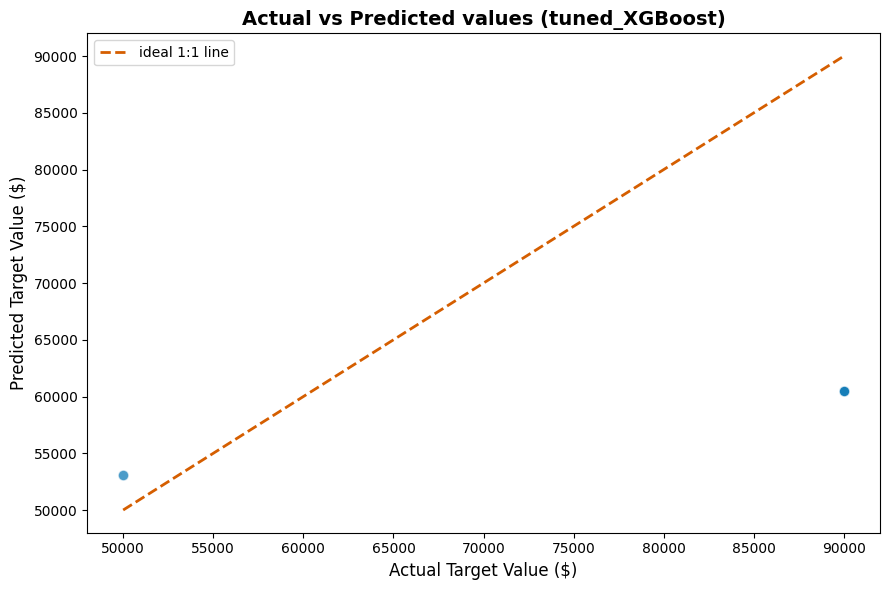

In [ ]:
import matplotlib.pyplot as plt

best_model_name = max(results, key=lambda k: results[k]['R2'])
best_preds = fitted_models[best_model_name].predict(x_test_proc)

# 1. Actual vs predicted value
plt.figure(figsize=(9, 6))
plt.scatter(y_test, best_preds, alpha=0.7, color='#0072B2', edgecolors='w', s=60)
min_val, max_val = min(y_test.min(), best_preds.min()), max(y_test.max(), best_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], color='#D55E00', linestyle='--', linewidth=2, label='ideal 1:1 line')
plt.title(f'Actual vs Predicted values ({best_model_name})', fontsize=14, fontweight='bold')
plt.xlabel('Actual Target Value ($)', fontsize=12)
plt.ylabel('Predicted Target Value ($)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

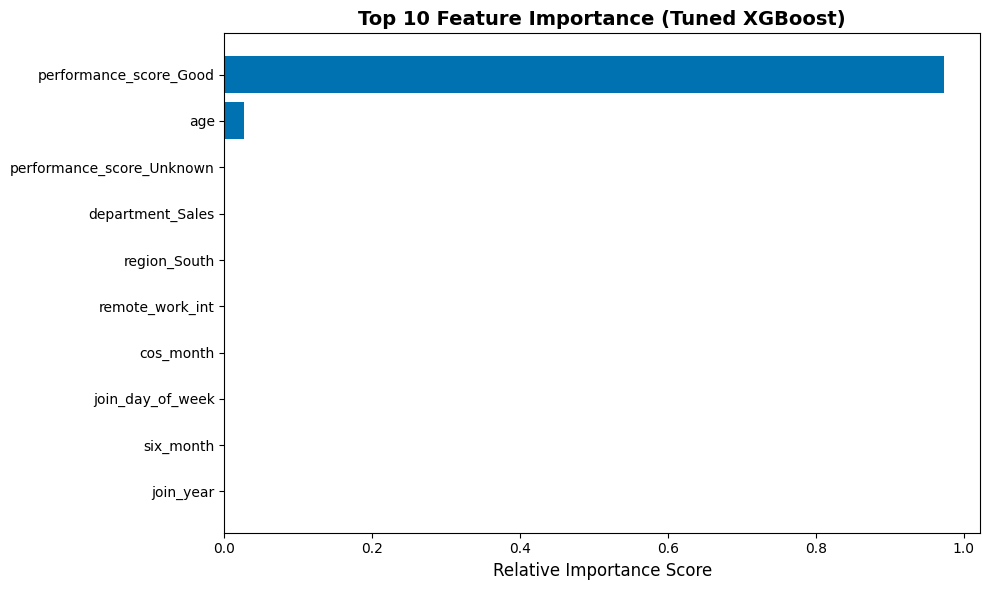

In [ ]:
# 2. Feature importance
import matplotlib.pyplot as plt
import pandas as pd

# Ensure we extract feature names from preprocessor safely if not already present in memory
if 'all_feature_names' not in locals():
    cat_encoder = preprocessor.named_transformers_['cat']
    encoded_cat_names = cat_encoder.get_feature_names_out(categorical_cols).tolist()
    all_feature_names = numeric_cols + encoded_cat_names

importance = best_xgb.feature_importances_
feature_imp_df = pd.DataFrame({'feature': all_feature_names, 'importance': importance}).sort_values('importance', ascending=True).tail(10)

plt.figure(figsize=(10, 6))
plt.barh(feature_imp_df['feature'], feature_imp_df['importance'], color='#0072B2')
plt.title('Top 10 Feature Importance (Tuned XGBoost)', fontsize=14, fontweight='bold')
plt.xlabel('Relative Importance Score', fontsize=12)
plt.tight_layout()
plt.show()